In [57]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [58]:
PROJECT_ROOT = Path("..")

DATA_DIR = PROJECT_ROOT / "data"

PROCESSED_DIR = DATA_DIR / "processed"

MODELS_DIR = PROJECT_ROOT / "models"

REPORTS_DIR = PROJECT_ROOT / "reports"

INTERPRETATION_DIR = REPORTS_DIR / "interpretation"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Reports:", REPORTS_DIR)
print("Models:", MODELS_DIR)

Project root: ..
Reports: ../reports
Models: ../models


In [59]:
print("Processed files:")
for path in sorted(PROCESSED_DIR.rglob("*")):
    if path.is_file():
        print(path)

print("\nReport files:")
for path in sorted(REPORTS_DIR.rglob("*")):
    if path.is_file():
        print(path)

Processed files:
../data/processed/X_test_baseline.csv
../data/processed/X_test_engineered.csv
../data/processed/X_test_raw_baseline.csv
../data/processed/X_test_raw_engineered.csv
../data/processed/X_train_baseline.csv
../data/processed/X_train_engineered.csv
../data/processed/X_train_raw_baseline.csv
../data/processed/X_train_raw_engineered.csv
../data/processed/baseline_preprocessor.joblib
../data/processed/engineered_preprocessor.joblib
../data/processed/ptbxl_metadata_explored.csv
../data/processed/ptbxl_test.csv
../data/processed/ptbxl_test_metadata.csv
../data/processed/ptbxl_train.csv
../data/processed/ptbxl_train_metadata.csv
../data/processed/ptbxl_val.csv
../data/processed/ptbxl_val_metadata.csv
../data/processed/y_test.csv
../data/processed/y_train.csv

Report files:
../reports/cardiovascular_final_results.csv
../reports/dataset_comparison.csv
../reports/final_results.json
../reports/histgradientboosting_predictions.csv
../reports/histgradientboosting_tuned_predictions.csv


In [60]:
cardio_test_path = PROCESSED_DIR / "cardio_test.csv"

if cardio_test_path.exists():

    cardio_test = pd.read_csv(cardio_test_path)

    print("Cardiovascular test shape:", cardio_test.shape)

else:

    cardio_test = None

    print("cardio_test.csv not found.")

cardio_test.csv not found.


In [61]:
interpretation_path = INTERPRETATION_DIR / "ptbxl_cnn_interpretation_summary.csv"

if interpretation_path.exists():

    interpretation_summary = pd.read_csv(interpretation_path)

    print(interpretation_summary.to_string(index=False))

else:

    interpretation_summary = None

    print("Interpretation summary not found.")

class top_lead  top_lead_importance
 NORM      aVR             0.151545
   MI       V2             0.067743
 STTC      aVR             0.187014
   CD       V1             0.100835
  HYP       V1             0.178855


In [62]:
ptbxl_metrics = pd.DataFrame(
    {
        "metric": [
            "ROC-AUC Macro",
            "ROC-AUC Micro",
            "Average Precision Macro",
            "Average Precision Micro",
            "F1 Macro",
            "F1 Micro",
        ],
        "value": [0.9015, 0.9185, 0.7618, 0.8239, 0.7036, 0.7489],
    }
)

ptbxl_metrics

,metric,value
0,ROC-AUC Macro,0.9015
1,ROC-AUC Micro,0.9185
2,Average Precision Macro,0.7618
3,Average Precision Micro,0.8239
4,F1 Macro,0.7036
5,F1 Micro,0.7489


In [63]:
ptbxl_class_metrics = pd.DataFrame(
    {
        "class": ["NORM", "MI", "STTC", "CD", "HYP"],
        "threshold": [0.47, 0.21, 0.42, 0.45, 0.23],
        "test_f1": [0.8444, 0.7259, 0.7517, 0.7330, 0.4632],
    }
)

ptbxl_class_metrics

,class,threshold,test_f1
0,NORM,0.47,0.8444
1,MI,0.21,0.7259
2,STTC,0.42,0.7517
3,CD,0.45,0.7330
4,HYP,0.23,0.4632


In [64]:
threshold_comparison = pd.DataFrame(
    {
        "approach": ["Fixed threshold = 0.5", "Validation-derived thresholds"],
        "test_macro_f1": [0.6470, 0.7036],
    }
)

threshold_comparison

,approach,test_macro_f1
0,Fixed threshold = 0.5,0.6470
1,Validation-derived thresholds,0.7036


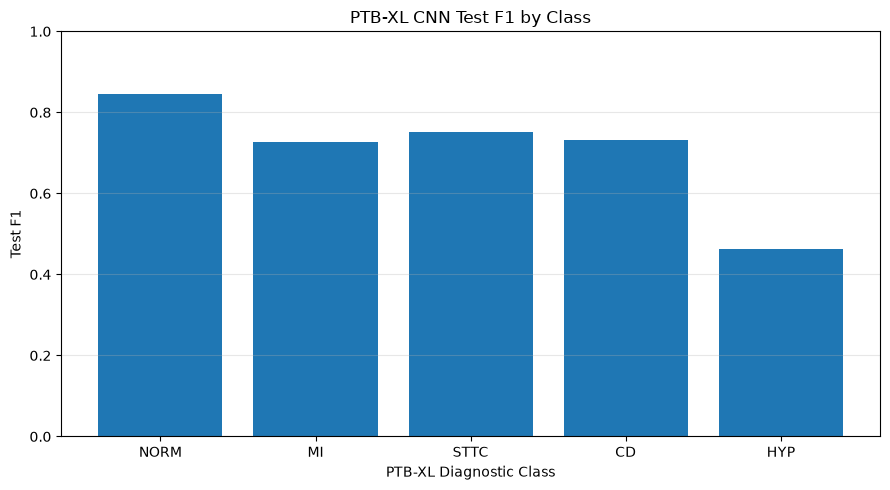

In [65]:
plt.figure(figsize=(9, 5))

plt.bar(ptbxl_class_metrics["class"], ptbxl_class_metrics["test_f1"])

plt.xlabel("PTB-XL Diagnostic Class")

plt.ylabel("Test F1")

plt.title("PTB-XL CNN Test F1 by Class")

plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

In [66]:
ptbxl_metrics.to_csv(REPORTS_DIR / "ptbxl_cnn_final_metrics.csv", index=False)

ptbxl_class_metrics.to_csv(REPORTS_DIR / "ptbxl_cnn_class_metrics.csv", index=False)

threshold_comparison.to_csv(REPORTS_DIR / "ptbxl_threshold_comparison.csv", index=False)

print("PTB-XL result files saved.")

PTB-XL result files saved.


In [67]:
candidate_metric_files = []

for path in REPORTS_DIR.rglob("*.csv"):

    name = path.name.lower()

    if any(
        keyword in name
        for keyword in ["metric", "model", "comparison", "baseline", "result"]
    ):
        candidate_metric_files.append(path)

print("Candidate result files:")

for path in candidate_metric_files:
    print(path)

Candidate result files:
../reports/logistic_tuning_results.csv
../reports/tabular_final_results.csv
../reports/tuning_comparison.csv
../reports/ptbxl_cnn_baseline_class_metrics.csv
../reports/histgradientboosting_tuning_results.csv
../reports/tabular_model_test_comparison.csv
../reports/methodology_comparison.csv
../reports/tabular_model_cv_comparison.csv
../reports/dataset_comparison.csv
../reports/ptbxl_threshold_comparison.csv
../reports/ptbxl_cnn_class_metrics.csv
../reports/ptbxl_cnn_final_class_metrics.csv
../reports/project_comparison.csv
../reports/ptbxl_cnn_baseline_training_history.csv
../reports/ptbxl_cnn_final_metrics.csv
../reports/cardiovascular_final_results.csv


In [68]:
for path in candidate_metric_files:

    print("\n" + "=" * 70)
    print(path)
    print("=" * 70)

    try:

        df = pd.read_csv(path)

        print(df.head(10).to_string(index=False))

    except Exception as e:

        print("Could not read:", e)


../reports/logistic_tuning_results.csv
 mean_fit_time  std_fit_time  mean_score_time  std_score_time  param_classifier__C                  params  split0_test_score  split1_test_score  split2_test_score  split3_test_score  split4_test_score  mean_test_score  std_test_score  rank_test_score
      0.260736      0.043339         0.030725        0.006381                 0.01 {'classifier__C': 0.01}           0.791359           0.790102           0.787485           0.786377           0.796602         0.790385        0.003582                8
      0.161186      0.009154         0.029878        0.002125                 0.05 {'classifier__C': 0.05}           0.791460           0.790229           0.787493           0.786609           0.796744         0.790507        0.003582                7
      0.172332      0.014870         0.036013        0.009079                 0.10  {'classifier__C': 0.1}           0.791461           0.790240           0.787482           0.786636           0.796752   

In [69]:
TABULAR_RESULTS_PATH = REPORTS_DIR / "tabular_model_test_comparison.csv"

tabular_results = pd.read_csv(TABULAR_RESULTS_PATH)

print("Loaded:", TABULAR_RESULTS_PATH)

print("\nShape:", tabular_results.shape)

print("\nColumns:")

print(tabular_results.columns.tolist())

print("\nResults:")

print(tabular_results.to_string(index=False))

Loaded: ../reports/tabular_model_test_comparison.csv

Shape: (3, 7)

Columns:
['model', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']

Results:
               model  accuracy  precision   recall       f1  roc_auc   pr_auc
 Logistic Regression  0.731260   0.760401 0.665280 0.709667 0.793824 0.773638
       Random Forest  0.712410   0.710329 0.704947 0.707628 0.766869 0.744146
HistGradientBoosting  0.736688   0.753429 0.693656 0.722308 0.803797 0.784888


In [70]:
tabular_results = pd.read_csv(TABULAR_RESULTS_PATH)

print(tabular_results.to_string(index=False))

               model  accuracy  precision   recall       f1  roc_auc   pr_auc
 Logistic Regression  0.731260   0.760401 0.665280 0.709667 0.793824 0.773638
       Random Forest  0.712410   0.710329 0.704947 0.707628 0.766869 0.744146
HistGradientBoosting  0.736688   0.753429 0.693656 0.722308 0.803797 0.784888


In [71]:
print(tabular_results.columns.tolist())

['model', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']


In [72]:
tabular_final = tabular_results[
    ["model", "accuracy", "precision", "recall", "f1", "roc_auc"]
].copy()

tabular_final

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.731260,0.760401,0.665280,0.709667,0.793824
1,Random Forest,0.712410,0.710329,0.704947,0.707628,0.766869
2,HistGradientBoosting,0.736688,0.753429,0.693656,0.722308,0.803797


In [73]:
tabular_final.to_csv(REPORTS_DIR / "cardiovascular_final_results.csv", index=False)

print("Saved cardiovascular final results.")

Saved cardiovascular final results.


In [74]:
project_comparison = pd.DataFrame(
    {
        "dataset": ["Cardiovascular Disease", "PTB-XL"],
        "input_type": ["Structured clinical/tabular data", "12-lead ECG signals"],
        "task": ["Binary classification", "Multi-label classification"],
        "model_family": ["Traditional ML", "1D CNN"],
        "target": ["cardio", "NORM / MI / STTC / CD / HYP"],
    }
)

project_comparison

,dataset,input_type,task,model_family,target
0,Cardiovascular Disease,Structured clinical/tabular data,Binary classification,Traditional ML,cardio
1,PTB-XL,12-lead ECG signals,Multi-label classification,1D CNN,NORM / MI / STTC / CD / HYP


In [75]:
print(project_comparison.to_string(index=False))

               dataset                       input_type                       task   model_family                      target
Cardiovascular Disease Structured clinical/tabular data      Binary classification Traditional ML                      cardio
                PTB-XL              12-lead ECG signals Multi-label classification         1D CNN NORM / MI / STTC / CD / HYP


In [76]:
dataset_comparison = pd.DataFrame(
    {
        "property": [
            "Data modality",
            "Approximate samples",
            "Number of input variables",
            "Prediction type",
            "Target",
        ],
        "cardiovascular": ["Tabular", 68205, 13, "Binary", "cardio"],
        "ptbxl": ["12-lead ECG", 21799, 12, "Multi-label", "NORM, MI, STTC, CD, HYP"],
    }
)

dataset_comparison

,property,cardiovascular,ptbxl
0,Data modality,Tabular,12-lead ECG
1,Approximate samples,68205,21799
2,Number of input variables,13,12
3,Prediction type,Binary,Multi-label
4,Target,cardio,"NORM, MI, STTC, CD, HYP"


In [77]:
methodology_comparison = pd.DataFrame(
    {
        "aspect": [
            "Preprocessing",
            "Feature representation",
            "Model",
            "Validation",
            "Final evaluation",
            "Interpretation",
        ],
        "cardiovascular": [
            "Cleaning + preprocessing + encoding/scaling",
            "Hand-defined tabular variables",
            "Traditional ML",
            "Stratified cross-validation",
            "Untouched test set",
            "Coefficients / feature importance",
        ],
        "ptbxl": [
            "ECG normalization",
            "Raw 12-lead signal",
            "1D CNN",
            "Train/validation/test split",
            "Untouched test set",
            "Gradient-based saliency",
        ],
    }
)

methodology_comparison

,aspect,cardiovascular,ptbxl
0,Preprocessing,Cleaning + preprocessing + encoding/scaling,ECG normalization
1,Feature representation,Hand-defined tabular variables,Raw 12-lead signal
2,Model,Traditional ML,1D CNN
3,Validation,Stratified cross-validation,Train/validation/test split
4,Final evaluation,Untouched test set,Untouched test set
5,Interpretation,Coefficients / feature importance,Gradient-based saliency


In [78]:
project_comparison.to_csv(REPORTS_DIR / "project_comparison.csv", index=False)

dataset_comparison.to_csv(REPORTS_DIR / "dataset_comparison.csv", index=False)

methodology_comparison.to_csv(REPORTS_DIR / "methodology_comparison.csv", index=False)

print("Comparison tables saved.")

Comparison tables saved.


In [79]:
if interpretation_summary is not None:

    print("PTB-XL CNN interpretation:")

    print(interpretation_summary.to_string(index=False))

PTB-XL CNN interpretation:
class top_lead  top_lead_importance
 NORM      aVR             0.151545
   MI       V2             0.067743
 STTC      aVR             0.187014
   CD       V1             0.100835
  HYP       V1             0.178855


In [80]:
print("=" * 70)
print("FINAL PROJECT SUMMARY")
print("=" * 70)

print("\n1. Cardiovascular tabular dataset")

print(
    "Structured demographic, physiological, "
    "and lifestyle variables were used to "
    "predict the binary cardiovascular target."
)

print("\n2. PTB-XL ECG dataset")

print(
    "A 1D CNN was trained directly on normalized "
    "12-lead ECG signals for multi-label "
    "diagnostic classification."
)

print("\n3. PTB-XL CNN test performance")

for _, row in ptbxl_metrics.iterrows():

    print(f"{row['metric']}: " f"{row['value']:.4f}")

print("\n4. Interpretation")

print(
    "The tabular models were interpreted using "
    "feature-level methods, while the CNN was "
    "interpreted using gradient-based ECG saliency."
)

FINAL PROJECT SUMMARY

1. Cardiovascular tabular dataset
Structured demographic, physiological, and lifestyle variables were used to predict the binary cardiovascular target.

2. PTB-XL ECG dataset
A 1D CNN was trained directly on normalized 12-lead ECG signals for multi-label diagnostic classification.

3. PTB-XL CNN test performance
ROC-AUC Macro: 0.9015
ROC-AUC Micro: 0.9185
Average Precision Macro: 0.7618
Average Precision Micro: 0.8239
F1 Macro: 0.7036
F1 Micro: 0.7489

4. Interpretation
The tabular models were interpreted using feature-level methods, while the CNN was interpreted using gradient-based ECG saliency.


In [81]:
import json

final_results = {
    "cardiovascular": {"models": tabular_final.to_dict(orient="records")},
    "ptbxl_cnn": {
        row["metric"]: float(row["value"]) for _, row in ptbxl_metrics.iterrows()
    },
}

if interpretation_summary is not None:
    final_results["ptbxl_interpretation"] = interpretation_summary.to_dict(
        orient="records"
    )

with open(REPORTS_DIR / "final_results.json", "w") as file:
    json.dump(final_results, file, indent=4)

print("Saved final_results.json")

Saved final_results.json


In [82]:
print("Final report files:")

for path in sorted(REPORTS_DIR.rglob("*")):

    if path.is_file():

        print(path.relative_to(REPORTS_DIR))

Final report files:
cardiovascular_final_results.csv
dataset_comparison.csv
final_results.json
histgradientboosting_predictions.csv
histgradientboosting_tuned_predictions.csv
histgradientboosting_tuning_results.csv
interpretation/lead_importance_NORM.csv
interpretation/ptbxl_cnn_interpretation_summary.csv
interpretation/ptbxl_cnn_lead_importance.csv
interpretation/saliency_NORM_sample_0.png
logistic_regression_coefficients.csv
logistic_regression_metrics.json
logistic_regression_predictions.csv
logistic_regression_tuned_predictions.csv
logistic_tuning_results.csv
methodology_comparison.csv
project_comparison.csv
ptbxl_cnn_baseline_class_metrics.csv
ptbxl_cnn_baseline_metrics.json
ptbxl_cnn_baseline_training_history.csv
ptbxl_cnn_class_metrics.csv
ptbxl_cnn_final_class_metrics.csv
ptbxl_cnn_final_metrics.csv
ptbxl_cnn_final_metrics.json
ptbxl_cnn_thresholds.json
ptbxl_diagnostic_class_counts.csv
ptbxl_diagnostic_class_definitions.csv
ptbxl_ecg_preprocessing_summary.json
ptbxl_exploratio